# Mind the Stability Gap, Part 3
### Climbing the electronegativity ladder, and where boron fits

**Author:** James Fox · Intro to AI & Machine Learning, Fall 2026

Parts [1](perovskite_stability_gap.ipynb) and [2](02_structure_composition_and_better_models.ipynb) looked at *how* perovskite stability gets reported. This part looks at the chemistry of the **X-site anion**, the "X" in ABX₃.

The electronegativity of the X-site anion is a dial:
- **Less electronegative anions** (iodide) hold their electrons loosely. That gives a small band gap, which is good for absorbing sunlight, but also soft bonds that make the material easy to degrade.
- **More electronegative anions** (bromide, chloride, oxide, fluoride) hold on tighter. That means wider gaps and stiffer bonds.

This notebook asks three questions:
1. How much of the possible anion chemistry has the field actually tried?
2. When iodide is partly replaced by more electronegative bromide, what happens to band gap, efficiency, and lifetime in real devices?
3. Which anions even *fit* the perovskite geometry, and where does boron come in?

## 1. Setup

In [1]:
%pip install -q lifelines

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Standard data-science stack; everything here comes pre-installed in Google Colab.
import os, re, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)

# Chart style: quiet axes and gridlines so the data does the talking
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ab"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 11, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
SOURCE = "Source: The Perovskite Database (Jacobsson et al., Nature Energy 2022), CC BY 4.0"
thousands = lambda v, _: f"{v/1000:g}K" if v >= 1000 else f"{v:.0f}"

pct = lambda share: f"{share:.0%}" if share >= 0.005 else "<1%"

def save(fig, name):
    # Saves each chart as a high-resolution PNG in figures/ (ready for LinkedIn)
    fig.savefig(f"figures/{name}.png")
    plt.show()

def hbars(ax, labels, values, fmt, color=BLUE, pad=0.01, span=None):
    # Horizontal bars, top-to-bottom in the order given, with the value printed at each bar's tip
    y = np.arange(len(values))[::-1]
    ax.barh(y, values, height=0.55, color=color)
    span = span or (max(values) if max(values) > 0 else 1)
    for yi, v in zip(y, values):
        ax.text(v + span * pad, yi, fmt(v), va="center", fontsize=10, color=INK_2)
    ax.set_yticks(y, labels)
    ax.set_xlim(0, span * 1.3)
    ax.grid(axis="y", visible=False)

In [3]:
from lifelines import KaplanMeierFitter

## 2. Get the data

In [4]:
DATA_URL = ("https://zenodo.org/records/5837035/files/"
            "Jesperkemist/perovskitedatabase_data-v1.0.1.zip?download=1")
ZIP_PATH = "perovskitedatabase_data-v1.0.1.zip"
CSV_NAME = "Perovskite_database_content_all_data.csv"

if not os.path.exists(ZIP_PATH):
    print("Downloading the Perovskite Database snapshot from Zenodo (about 3 MB)...")
    try:
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    except Exception as err:
        raise RuntimeError(
            f"Download failed ({err}). Open this link in your browser:\n{DATA_URL}\n"
            "then drag the zip into Colab's Files panel (folder icon, left side) and re-run this cell.")

with zipfile.ZipFile(ZIP_PATH) as zf:
    member = next(name for name in zf.namelist() if name.endswith(CSV_NAME))
    raw = pd.read_csv(zf.open(member), low_memory=False)

print(f"Loaded {len(raw):,} devices x {raw.shape[1]} columns")
raw[["Ref_DOI_number", "Ref_publication_date", "Cell_architecture",
     "Perovskite_composition_short_form", "JV_default_PCE", "Stability_measured"]].head()

Loaded 42,443 devices x 410 columns


,Ref_DOI_number,Ref_publication_date,Cell_architecture,Perovskite_composition_short_form,JV_default_PCE,Stability_measured
0,10.1021/jp5126624,2015-01-06,nip,CsSnI,0.00,False
1,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.00,False
2,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.13,False
3,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.12,False
4,10.1021/jp5126624,2015-01-06,nip,CsSnBr,0.10,False


## 3. Clean it up (same as Part 1)

In [5]:
MISSING = {"", "nan", "none", "unknown", "n/a", "na", "-"}

def get(name):
    # Returns a column, or an all-empty column if this snapshot doesn't have it
    return raw[name] if name in raw.columns else pd.Series(np.nan, index=raw.index)

def reported(series):
    # True where a cell holds real information rather than one of the 'missing' markers
    def check(v):
        if pd.isna(v):
            return False
        return any(tok.strip().lower() not in MISSING for tok in re.split(r"[;|>]+", str(v)))
    return series.map(check).astype(bool)

def to_bool(series):
    return series.astype(str).str.strip().str.lower().isin(["true", "1", "yes"])

def to_num(series):
    # Numbers stay numbers; text like '1.6 | nan' falls back to its first number
    direct = pd.to_numeric(series, errors="coerce")
    first = pd.to_numeric(series.astype(str).str.extract(r"(-?\d+(?:\.\d+)?)")[0], errors="coerce")
    return direct.fillna(first)

def range_max(series):
    # Largest number in a 'min; max' range ('25; 85' -> 85)
    def f(v):
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(v))
        return max(map(float, nums)) if nums else np.nan
    return series.map(f)

def text(series):
    return series.where(reported(series), "").astype(str).str.strip().str.lower()

def atmosphere_group(v):
    tokens = {t.strip() for t in re.split(r"[;|]", v) if t.strip()}
    if not tokens:
        return "Not reported"
    if tokens <= {"n2", "ar", "argon", "vacuum", "he", "inert"}:
        return "Inert (N2/Ar/vacuum)"
    if "dry air" in tokens:
        return "Dry air"
    if tokens & {"air", "ambient"}:
        return "Air / ambient"
    return "Other"

def bias_group(v):
    if not v:
        return "Not reported"
    for key, label in [("mpp", "MPP tracking"), ("open", "Open circuit"),
                       ("short", "Short circuit"), ("constant", "Constant bias")]:
        if key in v:
            return label
    return "Other"

TEST_TYPES = {  # ISOS category -> plain-English test type (conditions from Khenkin et al. 2020, Table 1)
    "d1": "Dark, room temperature (shelf life)",
    "d2": "Dark, heated to 65-85 °C",
    "d3": "Dark, 65-85 °C and 85% humidity (damp heat)",
    "l1": "Under light, room temperature",
    "l2": "Under light, heated to 65-85 °C",
    "l3": "Under light, heated, ~50% humidity",
    "o":  "Outdoors",
}
def test_type(v):
    v = v.replace("‐", "-").replace("‑", "-").replace(" ", "")   # some entries use unicode hyphens
    if not v:
        return "Not classified"
    m = re.match(r"isos-(lc|[dlotv])-?(\d)", v)
    if not m:
        return "Cycling, bias, IEC or other"
    kind = m.group(1) if m.group(1) == "o" else m.group(1) + m.group(2)
    return TEST_TYPES.get(kind, "Cycling, bias, IEC or other")

In [6]:
df = pd.DataFrame(index=raw.index)

# Who published it, and when
doi = text(get("Ref_DOI_number"))
df["paper"] = np.where(doi != "", doi, "no-doi-" + get("Ref_ID").astype(str))
df["year"] = pd.to_numeric(get("Ref_publication_date").astype(str)
                           .str.extract(r"((?:19|20)\d{2})")[0], errors="coerce")

# The device
df["architecture"] = text(get("Cell_architecture")).replace("", "not reported")
top_comps = text(get("Perovskite_composition_short_form")).value_counts().head(12).index
df["composition"] = text(get("Perovskite_composition_short_form")).where(lambda s: s.isin(top_comps), "other")
df["band_gap"] = to_num(get("Perovskite_band_gap")).where(lambda s: s.between(0.5, 4))
df["area_cm2"] = to_num(get("Cell_area_measured")).where(lambda s: s > 0)
df["pce"] = to_num(get("JV_default_PCE")).where(lambda s: s > 0)
df["encapsulated"] = to_bool(get("Encapsulation"))
df["module"] = to_bool(get("Module"))
df["outdoor"] = to_bool(get("Outdoor_tested"))

# The stability test
df["stability_tested"] = to_bool(get("Stability_measured"))
df["t80"] = to_num(get("Stability_PCE_T80")).where(lambda s: s > 0)
df["end_pct"] = to_num(get("Stability_PCE_end_of_experiment")).where(lambda s: s >= 0)
df["pce_initial"] = to_num(get("Stability_PCE_initial_value")).where(lambda s: s > 0).fillna(df["pce"])
df["duration_h"] = to_num(get("Stability_time_total_exposure")).where(lambda s: s > 0)
df["light_mw"] = to_num(get("Stability_light_intensity")).where(lambda s: s >= 0)
df["temp_max_c"] = range_max(get("Stability_temperature_range"))
df["rh_pct"] = to_num(get("Stability_relative_humidity_average_value")).fillna(
    range_max(get("Stability_relative_humidity_range")))
df["atmosphere"] = text(get("Stability_atmosphere")).map(atmosphere_group)
df["bias"] = text(get("Stability_potential_bias_load_condition")).map(bias_group)
dark = text(get("Stability_light_source_type")).str.contains("dark") | (df["light_mw"] == 0)
df["light_condition"] = np.select([dark, df["light_mw"] > 0], ["Dark", "Illuminated"], "Not reported")
df["test_type"] = text(get("Stability_protocol")).map(test_type)

tested = df[df["stability_tested"]]
print(f"{len(df):,} devices from {df['paper'].nunique():,} papers")
print(f"{len(tested):,} devices ({len(tested)/len(df):.1%}) have some kind of stability test")

42,443 devices from 7,358 papers
7,419 devices (17.5%) have some kind of stability test


## 4. The anion ladder

These are reference values from standard tables: Pauling electronegativities, Shannon ionic radii, and typical band gaps reported in the literature. One counterintuitive point: the **less** electronegative an atom, the **bigger** its anion. Fewer protons are holding the same number of electrons, so the electron cloud spreads out. That's why N³⁻ is slightly larger than O²⁻, and I⁻ is the largest of all.

In [7]:
ladder = pd.DataFrame([
    ("F⁻",  3.98, 1.33, "wide-gap insulators (e.g. KMgF₃)"),
    ("O²⁻", 3.44, 1.40, "~3.2 eV (SrTiO₃)"),
    ("Cl⁻", 3.16, 1.81, "~3.0 eV (MAPbCl₃)"),
    ("N³⁻", 3.04, 1.46, "~2.1 eV (oxynitride LaTiO₂N)"),
    ("Br⁻", 2.96, 1.96, "~2.3 eV (MAPbBr₃)"),
    ("I⁻",  2.66, 2.20, "~1.6 eV (MAPbI₃), ideal for one-junction solar"),
], columns=["Anion", "Electronegativity (Pauling)", "Ionic radius (Å)", "Typical perovskite band gap"]).set_index("Anion")
ladder

,Electronegativity (Pauling),Ionic radius (Å),Typical perovskite band gap
Anion,,,
F⁻,3.98,1.33,wide-gap insulators (e.g. KMgF₃)
O²⁻,3.44,1.40,~3.2 eV (SrTiO₃)
Cl⁻,3.16,1.81,~3.0 eV (MAPbCl₃)
N³⁻,3.04,1.46,~2.1 eV (oxynitride LaTiO₂N)
Br⁻,2.96,1.96,~2.3 eV (MAPbBr₃)
I⁻,2.66,2.20,"~1.6 eV (MAPbI₃), ideal for one-junction solar"


## 5. How much of the anion chemistry has been tried?

For every device, check which anions sit at its X-site. Pseudohalides are small molecular anions that behave like halides: thiocyanate (SCN⁻), hexafluorophosphate (PF₆⁻), and tetrafluoroborate (BF₄⁻), which contains **boron**.

99.6% of devices use nothing but iodide and/or bromide at the X-site.


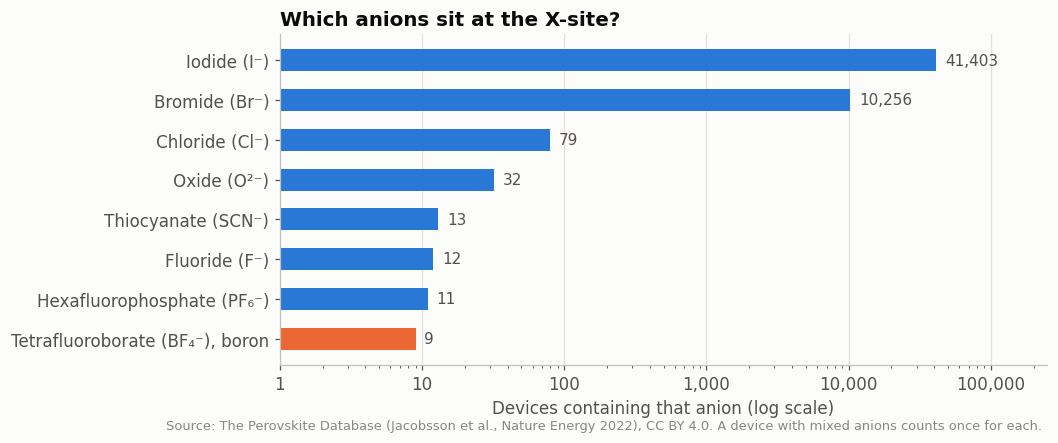

In [8]:
xs = get("Perovskite_composition_c_ions").fillna("").astype(str).str.replace(r"[()]", "", regex=True)
x_tokens = xs.map(lambda s: {t.strip() for t in re.split(r"[;|]", s) if t.strip()})
X_LABELS = {"I": "Iodide (I⁻)", "Br": "Bromide (Br⁻)", "Cl": "Chloride (Cl⁻)", "O": "Oxide (O²⁻)",
            "SCN": "Thiocyanate (SCN⁻)", "PF6": "Hexafluorophosphate (PF₆⁻)", "F": "Fluoride (F⁻)",
            "BF4": "Tetrafluoroborate (BF₄⁻), boron"}
x_counts = pd.Series({label: int(x_tokens.map(lambda t: key in t).sum()) for key, label in X_LABELS.items()})
x_counts = x_counts.sort_values(ascending=False)
only_i_br = x_tokens.map(lambda t: bool(t) and t <= {"I", "Br"}).mean()
print(f"{only_i_br:.1%} of devices use nothing but iodide and/or bromide at the X-site.")

fig, ax = plt.subplots(figsize=(9, 3.9))
y = np.arange(len(x_counts))[::-1]
colors = [ORANGE if "boron" in k else BLUE for k in x_counts.index]
ax.barh(y, x_counts.values, height=0.55, color=colors)
for yi, n in zip(y, x_counts.values):
    ax.text(n * 1.15, yi, f"{n:,}", va="center", fontsize=10, color=INK_2)
ax.set_yticks(y, x_counts.index)
ax.set_xscale("log")
ax.set_xlim(1, x_counts.max() * 6)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Devices containing that anion (log scale)")
ax.set_title("Which anions sit at the X-site?")
fig.text(0.01, -0.04, SOURCE + ". A device with mixed anions counts once for each.", fontsize=8.5, color=MUTED)
save(fig, "11_xsite_anions_explored")

## 6. Turning the dial: replacing iodide with bromide

Bromide is the one step up the ladder with enough data to study. For each device, compute the **bromide share of the halide**. For example, FAPbI₂.₅₅Br₀.₄₅ has 0.45 of 3 halides as bromide, so 15%. Then look at three things:
- **Band gap:** only *measured* values (absorption, EQE, Tauc plots). The database also estimates many gaps from composition alone, and using those would be circular.
- **Efficiency:** as reported.
- **Lifetime:** Kaplan–Meier medians from Part 2, using the same tests in air, with devices that outlasted their test still counted.

In [9]:
def bromide_share(ions, coefs):
    ions, coefs = str(ions), str(coefs)
    if "|" in ions or "|" in coefs or ions in ("", "nan"):
        return np.nan                                    # skip multi-layer entries
    names, nums = [s.strip() for s in ions.split(";")], [s.strip() for s in coefs.split(";")]
    if len(names) != len(nums):
        return np.nan
    try:
        amounts = dict(zip(names, map(float, nums)))
    except ValueError:
        return np.nan
    total = sum(amounts.values())
    if total <= 0 or not set(amounts) <= {"I", "Br", "Cl"}:
        return np.nan
    return amounts.get("Br", 0) / total

df["br_share"] = [bromide_share(a, b) for a, b in
                  zip(get("Perovskite_composition_c_ions"), get("Perovskite_composition_c_ions_coefficients"))]
basis = text(get("Perovskite_band_gap_estimation_basis"))
measured = basis.str.contains("absorption|eqe|tauc|pl|ups") & ~basis.str.contains("composition")
gap = to_num(get("Perovskite_band_gap"))
df["gap_measured"] = gap.where(measured & gap.between(1.0, 3.5))

BINS = [-0.001, 0.0001, 0.1, 0.2, 0.5, 0.9999, 1.0]
BIN_LABELS = ["0%", "0–10%", "10–20%", "20–50%", "50–99%", "100%"]
df["br_bin"] = pd.cut(df["br_share"], BINS, labels=BIN_LABELS)

# Survival setup, same as Part 2
tested = df[df["stability_tested"]].copy()
line = tested["duration_h"] * 20 / (100 - tested["end_pct"]).clip(lower=20)
tested["time"] = np.select([tested["t80"].notna(), tested["end_pct"].ge(80), tested["end_pct"].lt(80)],
                           [tested["t80"], tested["duration_h"], line], np.nan)
tested["event"] = np.select([tested["t80"].notna(), tested["end_pct"].ge(80), tested["end_pct"].lt(80)],
                            [1, 0, 1], 0).astype(bool)
surv = tested[tested["time"].gt(0)].copy()
protocol = text(get("Stability_protocol")).str.replace("‐", "-", regex=False).str.replace(" ", "", regex=False)
surv["inert_test"] = protocol.loc[surv.index].str.match(r"isos-[a-z]+-?\d+i$")
SHELF = surv["test_type"].eq(TEST_TYPES["d1"]) & ~surv["inert_test"]
LIGHT = surv["test_type"].eq(TEST_TYPES["l1"]) & ~surv["inert_test"]

MIN_N = 25
def km_median(sub):
    if len(sub) < MIN_N:
        return np.nan
    return KaplanMeierFitter().fit(sub["time"], sub["event"]).median_survival_time_

rows = []
for b in BIN_LABELS:
    members = df[df["br_bin"] == b]
    s_dark, s_light = surv[SHELF & (surv["br_bin"] == b)], surv[LIGHT & (surv["br_bin"] == b)]
    rows.append({"Bromide share": b, "Devices": len(members),
                 "Measured gaps": int(members["gap_measured"].notna().sum()),
                 "Median band gap (eV)": members["gap_measured"].median() if members["gap_measured"].notna().sum() >= 10 else np.nan,
                 "Median efficiency (%)": members["pce"].median(),
                 "Dark tests": len(s_dark), "Median life, dark (h)": km_median(s_dark),
                 "Light tests": len(s_light), "Median life, light (h)": km_median(s_light)})
ladder_data = pd.DataFrame(rows).set_index("Bromide share")
ladder_data.style.format({"Devices": "{:,}", "Dark tests": "{:,}", "Light tests": "{:,}", "Median band gap (eV)": "{:.2f}", "Median efficiency (%)": "{:.1f}",
                          "Median life, dark (h)": "{:,.0f}", "Median life, light (h)": "{:,.0f}"},
                         na_rep="too few").format(lambda v: "not reached" if np.isinf(v) else f"{v:,.0f}",
                                                  subset=["Median life, dark (h)", "Median life, light (h)"], na_rep="too few")

,Devices,Measured gaps,Median band gap (eV),Median efficiency (%),Dark tests,"Median life, dark (h)",Light tests,"Median life, light (h)"
Bromide share,,,,,,,,
0%,"32,048",609,1.60,12.2,"2,694",432,622,82
0–10%,"1,551",18,1.58,16.4,157,940,45,240
10–20%,"5,826",167,1.61,16.7,687,960,147,293
20–50%,"1,206",62,1.89,12.2,140,720,27,52
50–99%,444,16,2.09,6.1,42,"1,091",7,too few
100%,947,35,2.31,5.5,105,not reached,20,too few


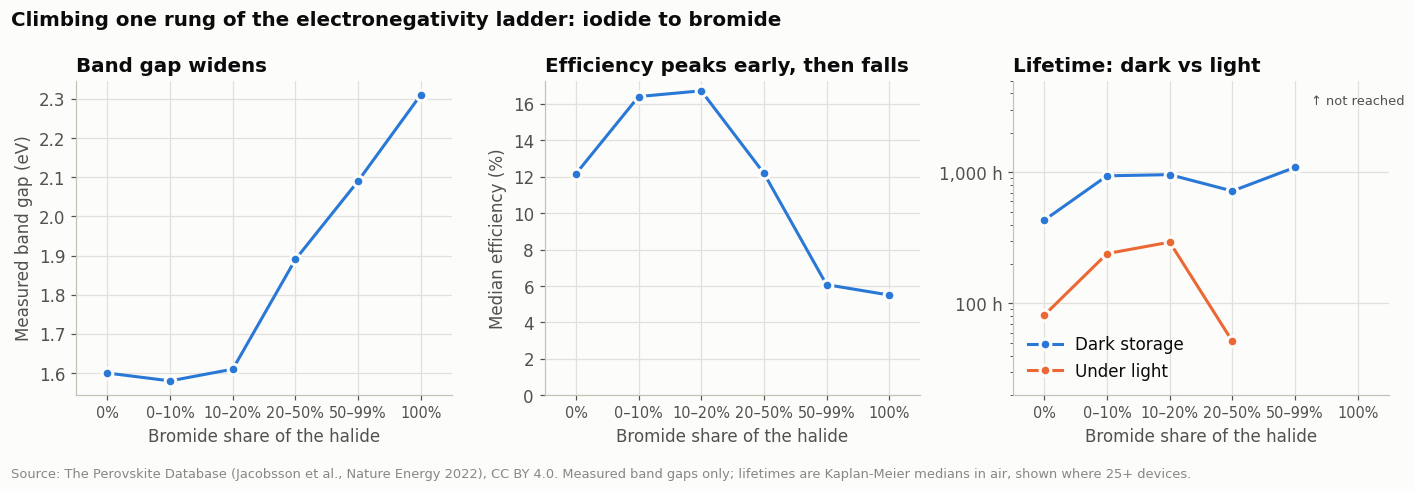

In [10]:
x = np.arange(len(BIN_LABELS))
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 4.2))
def dots(ax, values, color, label=None):
    v = np.asarray(values, dtype=float)
    ok = np.isfinite(v)
    ax.plot(x[ok], v[ok], color=color, lw=2, marker="o", ms=7, mec=SURFACE, mew=2, label=label)
    return v

dots(a1, ladder_data["Median band gap (eV)"], BLUE)
a1.set_title("Band gap widens")
a1.set_ylabel("Measured band gap (eV)")

dots(a2, ladder_data["Median efficiency (%)"], BLUE)
a2.set_title("Efficiency peaks early, then falls")
a2.set_ylabel("Median efficiency (%)")
a2.set_ylim(0, None)

dark = dots(a3, ladder_data["Median life, dark (h)"], BLUE, "Dark storage")
light = dots(a3, ladder_data["Median life, light (h)"], ORANGE, "Under light")
a3.set_yscale("log")
a3.set_ylim(20, 5000)
for i, v in enumerate(ladder_data["Median life, dark (h)"]):
    if np.isinf(v):   # more than half the group outlasted its test, so the median can't be pinned down
        a3.annotate("↑ not reached", (x[i], 3500), ha="center", va="center", fontsize=8.5, color=INK_2)
a3.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f} h")
a3.set_title("Lifetime: dark vs light")
a3.legend(frameon=False, loc="lower left")
for ax in (a1, a2, a3):
    ax.set_xticks(x, BIN_LABELS, fontsize=9.5)
    ax.set_xlabel("Bromide share of the halide")
    ax.set_xlim(-0.5, len(x) - 0.5)
fig.suptitle("Climbing one rung of the electronegativity ladder: iodide to bromide", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.text(0.01, -0.03, SOURCE + ". Measured band gaps only; lifetimes are Kaplan-Meier medians in air, shown where 25+ devices.",
         fontsize=8.5, color=MUTED)
save(fig, "12_iodide_to_bromide_tradeoff")

**Reading this.**
- **The band gap follows the ladder.** Swapping iodide for the more electronegative bromide widens the gap from about 1.6 eV to about 2.3 eV, just as the reference table predicts.
- **Efficiency peaks at a small bromide share (up to about 20%).** That's where the popular mixed-cation recipes sit. Beyond it, the wider gap wastes more of the red end of sunlight.
- **In the dark, bromide helps.** Lifetimes roughly double compared with pure iodide, and more than half of pure-bromide devices outlasted their tests.
- **Under light, mid-range mixtures stumble.** Devices with 20–50% bromide fail far sooner than those with 10–20%, and even sooner than pure iodide. That's consistent with a known effect called **light-induced halide segregation** (the "Hoke effect"): under illumination, mixed iodide/bromide films un-mix into iodide-rich and bromide-rich patches, and the iodide-rich patches trap charge. Sample sizes here are small, so treat this as a hint, not a measurement.

This is the catch with mixing anions to get the best of both: the mixture itself can become a new way to fail.

## 7. Which anions even fit? The tolerance factor

A 3D perovskite only forms when the ions fit together. The **Goldschmidt tolerance factor** checks this with simple geometry:

$$t = \frac{r_A + r_X}{\sqrt{2}\,(r_B + r_X)}$$

Values between about **0.8 and 1.0** usually give a 3D perovskite. Too big and the structure goes layered. Too small and it collapses into a different, non-perovskite phase.

Below, lead (Pb²⁺) is held at the B-site while the A-site cation and the X-site anion are varied. This includes **borohydride (BH₄⁻)**, a boron-centered anion, using its effective radius from Kieslich, Sun & Cheetham (2015).

In [11]:
R_A = {"Cs⁺": 1.88, "MA⁺": 2.17, "FA⁺": 2.53}                                   # Å; Shannon (Cs, CN12) / Kieslich 2015
R_X = {"F⁻": 1.33, "Cl⁻": 1.81, "BH₄⁻ (boron)": 2.03, "Br⁻": 1.96, "I⁻": 2.20}   # Å; Shannon / Kieslich 2015
R_PB = 1.19                                                                       # Å; Pb²⁺, CN6
tf = pd.DataFrame({a: {x: (ra + rx) / (np.sqrt(2) * (R_PB + rx)) for x, rx in R_X.items()} for a, ra in R_A.items()})
tf.index.name = "X-site anion  \\  A-site cation"
def shade(v):
    return "background-color: #cde2fb" if 0.8 <= v <= 1.0 else "color: #898781"
tf.style.format("{:.2f}").map(shade)

,Cs⁺,MA⁺,FA⁺
X-site anion \ A-site cation,,,
F⁻,0.90,0.98,1.08
Cl⁻,0.87,0.94,1.02
BH₄⁻ (boron),0.86,0.92,1.00
Br⁻,0.86,0.93,1.01
I⁻,0.85,0.91,0.99


Shaded cells fall in the 0.8–1.0 window. Two things stand out:
- **Geometry isn't what rules out fluoride.** F⁻ fits fine with Cs⁺ and MA⁺. Fluoride is ruled out for solar by electronegativity: it holds its electrons so tightly that the band gap becomes enormous.
- **Borohydride fits like a halide.** BH₄⁻ sits between bromide and iodide in size. It lands in the window with Cs⁺ and MA⁺ and right at the edge with FA⁺, the same pattern as bromide and iodide. A whole family of perovskite-type borohydrides exists (Schouwink *et al.*, 2014), including mixed BH₄⁻/halide versions. But BH₄⁻ is a strong reducing agent and reacts with water, so geometry says yes while chemistry adds big caveats, especially next to easily reduced lead(II).

## 8. Where boron fits

**As a bare anion, boron is too electropositive.** Its electronegativity (2.04) is lower than carbon's (2.55) and close to hydrogen's. In metal borides it doesn't form isolated anions. It builds B–B networks instead.

**Its real talent is electron deficiency.** Boron has three valence electrons and an empty p orbital, so it shares electrons in unusual ways, including three-center, two-electron bonds. That lets it form **cluster anions that spread a negative charge over many atoms**: BH₄⁻, BF₄⁻, closo-borates like B₁₂H₁₂²⁻, and carboranes like CB₁₁H₁₂⁻. These are about the most charge-diffuse, weakly coordinating anions known, which is the "electronegative cluster" idea in practice.

**Where it already matters for energy:**
- **Silicon solar cells (a stability story).** Boron was the standard p-type dopant in silicon for about 20 years. Under light, boron pairs with oxygen impurities to form a defect that drains power, known as light-induced degradation. Once gallium-doping patents expired in May 2020, the industry switched quickly, and by one manufacturer's estimate about 80% of panels made in 2021 used gallium instead.
- **This database.** BF₄⁻ sits at the X-site in only a handful of devices. Boron compounds also appear as additives: BF₄⁻ salts, a borate dopant for hole-transport layers, boronic acids for surface passivation, and a boron subphthalocyanine layer.
- **Batteries.** Closo-borate and carborane salts are *superionic* solid electrolytes. The big, diffuse cluster anions rotate and let Li⁺, Na⁺, or Ca²⁺ move through the solid quickly.
- **Hydrogen storage.** Borohydrides hold a lot of hydrogen by weight. The perovskite-type borohydrides above were studied partly for this.

**Open questions worth checking in the literature (speculative, not results):**
- Could chemically robust cluster anions like closo-borates act as bulky, water-repelling surface passivators or spacer layers on halide perovskites?
- Could partial BF₄⁻ substitution, like the SCN⁻ results in Part 2, improve moisture tolerance without triggering halide segregation?

In [12]:
s3 = {
    "share_devices_only_I_or_Br": only_i_br,
    "devices_with_BF4_xsite": int(x_counts.filter(like="boron").iloc[0]),
    "gap_iodide_only_eV": ladder_data.loc["0%", "Median band gap (eV)"],
    "gap_bromide_only_eV": ladder_data.loc["100%", "Median band gap (eV)"],
    "life_dark_iodide_h": ladder_data.loc["0%", "Median life, dark (h)"],
    "life_dark_10_20_h": ladder_data.loc["10–20%", "Median life, dark (h)"],
    "life_light_iodide_h": ladder_data.loc["0%", "Median life, light (h)"],
    "life_light_10_20_h": ladder_data.loc["10–20%", "Median life, light (h)"],
    "life_light_20_50_h": ladder_data.loc["20–50%", "Median life, light (h)"],
    "tf_MA_Pb_BH4": tf.loc["BH₄⁻ (boron)", "MA⁺"],
}
pd.Series(s3).to_csv("part3_summary.csv", header=["value"])
print(f"""
- {s3['share_devices_only_I_or_Br']:.1%} of devices use only iodide and/or bromide at the X-site; boron (BF₄⁻) appears in {s3['devices_with_BF4_xsite']}.
- Measured band gap: {s3['gap_iodide_only_eV']:.2f} eV (all iodide) to {s3['gap_bromide_only_eV']:.2f} eV (all bromide).
- Median life under light in air: {s3['life_light_iodide_h']:,.0f} h (all iodide), {s3['life_light_10_20_h']:,.0f} h (10-20% Br),
  {s3['life_light_20_50_h']:,.0f} h (20-50% Br).
- Borohydride's tolerance factor with MA and Pb: {s3['tf_MA_Pb_BH4']:.2f} (fits the 0.8-1.0 window).
""")


- 99.6% of devices use only iodide and/or bromide at the X-site; boron (BF₄⁻) appears in 9.
- Measured band gap: 1.60 eV (all iodide) to 2.31 eV (all bromide).
- Median life under light in air: 82 h (all iodide), 293 h (10-20% Br),
  52 h (20-50% Br).
- Borohydride's tolerance factor with MA and Pb: 0.92 (fits the 0.8-1.0 window).



## 9. Limitations and sources

- These are associations in published data. Bromide-containing recipes also differ in cations, labs, and years.
- The 20–50% bromide light result rests on about 27 devices.
- Tolerance factors are a rough geometric screen. They ignore bonding, and molecular ions like BH₄⁻ aren't true spheres.

**Sources:** Pauling electronegativities and Shannon ionic radii (standard tables). Kieslich, Sun & Cheetham, *Chem. Sci.* 2015, [doi:10.1039/c5sc00961h](https://doi.org/10.1039/c5sc00961h) (effective radii of MA⁺, FA⁺, BH₄⁻). Schouwink *et al.*, *Nat. Commun.* 5, 5706 (2014), [doi:10.1038/ncomms6706](https://doi.org/10.1038/ncomms6706) (perovskite-type borohydrides). Hoke *et al.*, *Chem. Sci.* 2015, [doi:10.1039/c4sc03141e](https://doi.org/10.1039/c4sc03141e) (light-induced halide segregation). Wright, Hallam & Vicari Stefani, *The Conversation* (2021), on boron–oxygen degradation and the switch to gallium doping. Oxynitride band gaps: *Mater. Chem. Front.* 2024, [doi:10.1039/d3qm01019h](https://doi.org/10.1039/d3qm01019h).